# Data analyser: explore an experiment

**Facilitator reference solution**

## Before you start
**Time:** 45–75 minutes. **Experience:** no previous Python required.

In Google Colab, open **File > Upload notebook** and select this `.ipynb` file. Save a copy to your Drive if needed. Run cells from top to bottom using the triangle beside each code cell or **Shift + Enter**. Text cells explain the next step. A variable is a name for a value; a function is a reusable set of instructions.

All example data are synthetic and generated inside this notebook. No uploads, paid tools, API keys or extra datasets are required. Imports use NumPy, pandas, Matplotlib and, for signal analysis, SciPy. If using a local Jupyter installation, install the packages listed in `requirements.txt` first.

**Your goal:** run the working example, make the guided changes, check the result, then personalise it for your subject. `TODO` comments identify changes to try. The starter already runs successfully before you edit it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})

## 1. Read a CSV table
A CSV is a text table with commas separating columns. This synthetic example compares reaction times under two conditions. Each row represents a different participant, so the groups are independent. These data cannot establish a real effect.

`pd.read_csv` converts CSV text into a DataFrame, Python’s table-like object. Replace the text with your own non-sensitive example later, keeping the column names or updating the code.

In [2]:
csv_text = """participant,condition,reaction_time_ms
1,Quiet,280
2,Quiet,310
3,Quiet,295
4,Quiet,330
5,Quiet,305
6,Quiet,290
7,Noise,340
8,Noise,365
9,Noise,320
10,Noise,390
11,Noise,350
12,Noise,335
"""
data = pd.read_csv(StringIO(csv_text))
print(data.to_string(index=False))

 participant condition  reaction_time_ms
           1     Quiet               280
           2     Quiet               310
           3     Quiet               295
           4     Quiet               330
           5     Quiet               305
           6     Quiet               290
           7     Noise               340
           8     Noise               365
           9     Noise               320
          10     Noise               390
          11     Noise               350
          12     Noise               335


## 2. Check the data
Missing values, wrong units and text in numeric columns can change your answer. This example stops with a helpful message if a required value is absent or invalid. It does not silently remove rows.

In [3]:
required = {'participant', 'condition', 'reaction_time_ms'}
if not required.issubset(data.columns):
    raise ValueError(f'Missing columns: {required - set(data.columns)}')
data['reaction_time_ms'] = pd.to_numeric(data['reaction_time_ms'], errors='raise')
if data[list(required)].isna().any().any():
    raise ValueError('Fill or explain missing values before continuing.')
if (data['reaction_time_ms'] <= 0).any():
    raise ValueError('Reaction times must be positive.')
print('Data checks passed.')

Data checks passed.


## 3. Calculate summaries
`groupby` groups rows with the same condition. `mean` is the average and `std` is the sample standard deviation, describing spread.

**Check:** the Quiet mean should be about 301.7 ms and Noise about 350.0 ms.

In [4]:
summary = data.groupby('condition')['reaction_time_ms'].agg(['count', 'mean', 'median', 'std'])
print(summary.round(2))
assert np.isclose(summary.loc['Quiet', 'mean'], 301.6666667)
assert np.isclose(summary.loc['Noise', 'mean'], 350.0)

           count    mean  median    std
condition                              
Noise          6  350.00   345.0  24.70
Quiet          6  301.67   300.0  17.51


## 4. Show individual results
A scatter plot shows every observation. Black horizontal lines show the group means. Avoid claiming statistical significance from this descriptive plot alone.

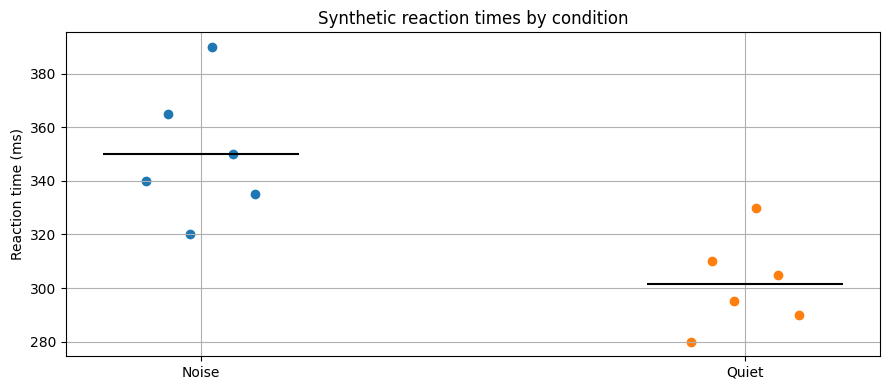

In [5]:
fig, ax = plt.subplots()
for position, (condition, group) in enumerate(data.groupby('condition')):
    jitter = np.linspace(-0.10, 0.10, len(group))
    ax.scatter(position + jitter, group['reaction_time_ms'], label=condition)
    ax.hlines(group['reaction_time_ms'].mean(), position-0.18, position+0.18, color='black')
ax.set_xticks(range(len(summary)), summary.index)
ax.set_ylabel('Reaction time (ms)')
ax.set_title('Synthetic reaction times by condition')
fig.tight_layout()
fig.savefig('reaction_times.png', dpi=160)
plt.show()
summary.to_csv('reaction_time_summary.csv')

## 5. Your tasks
- **Beginner:** change the graph title and point colours. Explain what the black lines represent.
- **Core:** calculate Noise mean minus Quiet mean. Is it positive or negative, and what does that mean?
- **Personalise:** adapt the table for plant height, rainfall, reaction yield or material strength. Update all column names, units and checks consistently.
- **Stretch:** add a box plot and compare its message with the individual-point plot.

**Hint:** access a value with `summary.loc['Noise', 'mean']`.

In [6]:
# TODO: replace None with your calculation.
mean_difference_ms = None
if mean_difference_ms is None:
    print('Add your calculation here when you are ready.')
else:
    print(f'Noise minus Quiet: {mean_difference_ms:.2f} ms')

Add your calculation here when you are ready.


## Worked extension
Use this after the guided activities. Other correct approaches are welcome.

Noise minus Quiet: 48.33 ms
The Noise group has a higher mean reaction time in this synthetic sample.


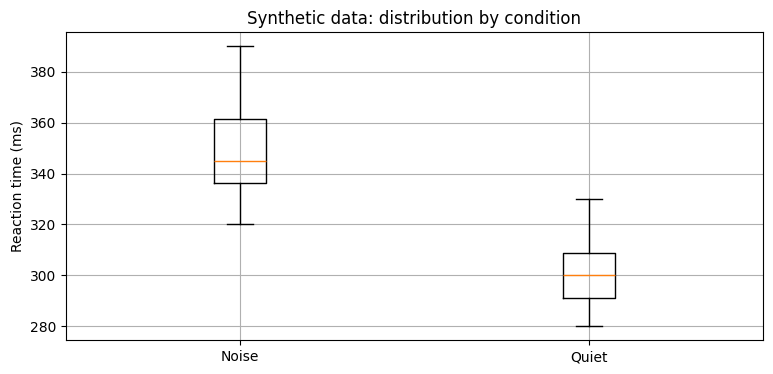

In [7]:
mean_difference_ms = summary.loc['Noise', 'mean'] - summary.loc['Quiet', 'mean']
assert np.isclose(mean_difference_ms, 48.3333333)
print(f'Noise minus Quiet: {mean_difference_ms:.2f} ms')
print('The Noise group has a higher mean reaction time in this synthetic sample.')
fig, ax = plt.subplots()
groups = [data.loc[data['condition'] == label, 'reaction_time_ms'].to_numpy() for label in summary.index]
ax.boxplot(groups, tick_labels=summary.index)
ax.set_ylabel('Reaction time (ms)')
ax.set_title('Synthetic data: distribution by condition')
plt.show()

## Save and explain your project
1. Give the notebook your own project title.
2. Add a text cell explaining the question, inputs, output and one limitation.
3. Restart the session/kernel and run every cell in order. Does it still work?
4. Download the notebook as `.ipynb` and save your output files from the file sidebar. In Colab, runtime files can disappear when the session ends.

**Reflection:** What did you change? How did you check it? What would you add next?